# 07 - WoE / IV Validation and Final Feature Selection

**Project:** German Credit Risk
**Inputs:** `data/processed/german_credit_engineered.csv` and `data/processed/woe_iv_tables.csv` (from notebook 05)
**Author:** Divya Akbari

**Goal of this notebook**
1. **Validate** the WoE / IV findings from notebooks 05 and 06: are they correct, reliable and stable?
2. **Finalise** the feature selection with clear evidence for every feature.
3. Save the **final feature list**.

| Test | Question it answers |
|---|---|
| 1. Reproducibility | Do the saved WoE / IV results match a fresh calculation from the data? |
| 2. Bootstrap confidence intervals | How much could each IV change with a different sample of customers? |
| 3. Noise floor | Is each IV larger than what pure chance would produce? |
| 4. Train / test stability | Do the WoE patterns hold on customers that were not used to calculate them? |
| 5. Population stability (PSI) | Are the bands spread the same way in different samples? |
| 6. Multicollinearity (VIF) | Do the selected features overlap too much? |
| 7. Significance in the model | Is every feature significant when all are used together? |
| 8. Hold-out performance | How well do the features predict on unseen customers, and does any feature set do better? |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option('display.width', 150)
pd.set_option('display.max_colwidth', None)

fe = pd.read_csv('data/processed/german_credit_engineered.csv')
fe['housing'] = fe['Housing']
fe['sex'] = fe['Sex']
saved = pd.read_csv('data/processed/woe_iv_tables.csv')
print(fe.shape, saved.shape)

(1000, 28) (37, 9)


In [2]:
names = {
    'checking_status': 'Checking account status', 'low_balance_profile': 'Low balance profile', 'duration_bin': 'Duration',
    'saving_status': 'Saving account status', 'credit_bin': 'Credit amount', 'age_bin': 'Age', 'housing': 'Housing',
    'payment_bin': 'Monthly payment', 'purpose_group': 'Purpose group', 'sex': 'Sex', 'job_group': 'Job group',
}
features = list(names)
selected = ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin', 'housing', 'payment_bin', 'purpose_group']

def woe_iv(data, feature):
    """Return the WoE of every band and the IV of the feature."""
    table = pd.crosstab(data[feature], data['bad'])
    good_share = (table[0] + 0.5) / table[0].sum()
    bad_share = (table[1] + 0.5) / table[1].sum()
    woe = np.log(good_share / bad_share)
    return woe, ((good_share - bad_share) * woe).sum()

iv_full = pd.Series({f: woe_iv(fe, f)[1] for f in features})

## 1. Reproducibility
The IV of every feature is recalculated from the engineered data and compared with the saved WoE / IV table.
The saved table was rounded to 4 decimals, so differences below 0.001 count as a match.

In [3]:
saved_iv = saved.groupby('Feature')['IV part'].sum()
repro = pd.DataFrame({'Feature': [names[f] for f in features], 'Saved IV': [round(saved_iv[f], 4) for f in features],
                      'Recalculated IV': [round(iv_full[f], 4) for f in features]})
repro['Difference'] = (repro['Recalculated IV'] - repro['Saved IV']).abs().round(4)
repro['Match'] = np.where(repro['Difference'] < 0.001, 'Yes', 'No')
repro

,Feature,Saved IV,Recalculated IV,Difference,Match
0,Checking account status,0.6621,0.6621,0.0000,Yes
1,Low balance profile,0.3266,0.3267,0.0001,Yes
2,Duration,0.2301,0.2301,0.0000,Yes
3,Saving account status,0.1885,0.1885,0.0000,Yes
4,Credit amount,0.1423,0.1422,0.0001,Yes
5,Age,0.0929,0.0929,0.0000,Yes
6,Housing,0.0842,0.0841,0.0001,Yes
7,Monthly payment,0.0771,0.0771,0.0000,Yes
8,Purpose group,0.0666,0.0665,0.0001,Yes
9,Sex,0.0267,0.0267,0.0000,Yes


## 2. Bootstrap confidence intervals
The 1,000 customers are resampled with replacement 500 times, and the IV is recalculated each time.
The middle 95% of these values gives a confidence interval for each IV.

In [4]:
rng = np.random.default_rng(42)
boot = {f: [] for f in features}
for _ in range(500):
    sample = fe.iloc[rng.integers(0, len(fe), len(fe))].reset_index(drop=True)
    for f in features:
        boot[f].append(woe_iv(sample, f)[1])

ci = pd.DataFrame({
    'Feature': [names[f] for f in features],
    'IV': [round(iv_full[f], 3) for f in features],
    'CI low (2.5%)': [round(np.percentile(boot[f], 2.5), 3) for f in features],
    'CI high (97.5%)': [round(np.percentile(boot[f], 97.5), 3) for f in features],
    'Chance IV below 0.02 (%)': [round(np.mean(np.array(boot[f]) < 0.02) * 100, 1) for f in features],
})
ci

,Feature,IV,CI low (2.5%),CI high (97.5%),Chance IV below 0.02 (%)
0,Checking account status,0.662,0.467,0.919,0.0
1,Low balance profile,0.327,0.198,0.507,0.0
2,Duration,0.230,0.128,0.382,0.0
3,Saving account status,0.189,0.100,0.344,0.0
4,Credit amount,0.142,0.062,0.286,0.0
5,Age,0.093,0.033,0.204,0.8
6,Housing,0.084,0.025,0.174,1.2
7,Monthly payment,0.077,0.023,0.171,1.8
8,Purpose group,0.066,0.026,0.172,1.2
9,Sex,0.027,0.001,0.090,40.8


## 3. Noise floor
If the target is shuffled at random, any IV that remains is pure chance. The target is shuffled 200 times;
the 95th percentile of these IVs is the **noise floor**. A real feature should have an IV well above it.

In [5]:
noise = {f: [] for f in features}
for _ in range(200):
    shuffled = fe.copy()
    shuffled['bad'] = rng.permutation(shuffled['bad'].values)
    for f in features:
        noise[f].append(woe_iv(shuffled, f)[1])

noise_floor = pd.Series({f: np.percentile(noise[f], 95) for f in features})
nf = pd.DataFrame({'Feature': [names[f] for f in features], 'IV': [round(iv_full[f], 3) for f in features],
                   'Noise floor (95%)': [round(noise_floor[f], 3) for f in features]})
nf['IV / noise floor'] = (nf['IV'] / nf['Noise floor (95%)']).round(1)
nf['Above noise'] = np.where(nf['IV'] > nf['Noise floor (95%)'], 'Yes', 'No')
nf

,Feature,IV,Noise floor (95%),IV / noise floor,Above noise
0,Checking account status,0.662,0.030,22.1,Yes
1,Low balance profile,0.327,0.016,20.4,Yes
2,Duration,0.230,0.030,7.7,Yes
3,Saving account status,0.189,0.038,5.0,Yes
4,Credit amount,0.142,0.037,3.8,Yes
5,Age,0.093,0.028,3.3,Yes
6,Housing,0.084,0.028,3.0,Yes
7,Monthly payment,0.077,0.023,3.3,Yes
8,Purpose group,0.066,0.042,1.6,Yes
9,Sex,0.027,0.018,1.5,Yes


Every selected feature is above its noise floor. **Purpose group** has the smallest margin (1.6 times its noise floor).
**Job group** is below its noise floor, so its IV is no larger than random chance would produce.
**Sex** is only just above its noise floor (1.5 times), and the bootstrap gives a 41% chance that its IV is below 0.02, so its signal is weak and unreliable.

## 4. Train / test stability and 5. PSI
The data is split 70 / 30 at random 50 times. For each split, WoE is calculated on the training part and on the test part separately.
- **WoE correlation:** do the bands rank in the same order of risk in both parts? (1.0 = identical pattern)
- **PSI** (Population Stability Index): do the bands hold similar shares of customers? Below 0.1 = stable, 0.1 to 0.25 = some shift, above 0.25 = unstable.

In [6]:
splits = StratifiedShuffleSplit(n_splits=50, test_size=0.3, random_state=1)
woe_corr = {f: [] for f in selected}
psi = {f: [] for f in selected}
iv_train = {f: [] for f in selected}
iv_test = {f: [] for f in selected}

for train_idx, test_idx in splits.split(fe, fe['bad']):
    train, test = fe.iloc[train_idx], fe.iloc[test_idx]
    for f in selected:
        w_train, i_train = woe_iv(train, f)
        w_test, i_test = woe_iv(test, f)
        woe_corr[f].append(np.corrcoef(w_train, w_test.reindex(w_train.index))[0, 1])
        p_train = train[f].value_counts(normalize=True)
        p_test = test[f].value_counts(normalize=True).reindex(p_train.index).fillna(0.0001)
        psi[f].append(((p_train - p_test) * np.log(p_train / p_test)).sum())
        iv_train[f].append(i_train)
        iv_test[f].append(i_test)

stability = pd.DataFrame({
    'Feature': [names[f] for f in selected],
    'Mean WoE correlation': [round(np.mean(woe_corr[f]), 3) for f in selected],
    'Lowest WoE correlation': [round(np.min(woe_corr[f]), 3) for f in selected],
    'Max PSI': [round(np.max(psi[f]), 3) for f in selected],
    'Mean IV (train)': [round(np.mean(iv_train[f]), 3) for f in selected],
    'Mean IV (test)': [round(np.mean(iv_test[f]), 3) for f in selected],
})
stability['Pattern'] = np.where(stability['Mean WoE correlation'] >= 0.8, 'Stable', 'Unstable')
stability

,Feature,Mean WoE correlation,Lowest WoE correlation,Max PSI,Mean IV (train),Mean IV (test),Pattern
0,Checking account status,0.940,0.668,0.053,0.666,0.688,Stable
1,Duration,0.925,0.729,0.050,0.241,0.259,Stable
2,Saving account status,0.817,0.179,0.057,0.200,0.208,Stable
3,Credit amount,0.880,0.432,0.060,0.151,0.171,Stable
4,Age,0.891,0.433,0.039,0.099,0.112,Stable
5,Housing,0.801,0.192,0.056,0.084,0.119,Stable
6,Monthly payment,0.899,0.313,0.047,0.077,0.115,Stable
7,Purpose group,0.557,-0.365,0.047,0.073,0.121,Unstable


- All PSI values are below 0.1, so the bands are spread the same way in every split.
- Seven features keep the same risk pattern (mean WoE correlation 0.80 or higher).
- **Purpose group** is the exception: its pattern is weak and in some splits even reverses (lowest correlation below 0).
- Test IVs are slightly higher than training IVs. This is expected: IV is biased upward in smaller samples, and the test parts hold only 300 customers.

## 6. Multicollinearity (VIF)
A Variance Inflation Factor (VIF) above 5 would mean a feature is largely explained by the others.

In [7]:
X = pd.DataFrame({f: fe[f].map(woe_iv(fe, f)[0]) for f in selected})
X_const = sm.add_constant(X)
vif = pd.DataFrame({'Feature': [names[f] for f in selected],
                    'VIF': [round(variance_inflation_factor(X_const.values, i + 1), 2) for i in range(len(selected))]})
max_corr = X.corr().abs().where(~np.eye(len(selected), dtype=bool)).max().max()
print('Highest correlation between two selected WoE features:', round(max_corr, 3))
vif

Highest correlation between two selected WoE features: 0.384


,Feature,VIF
0,Checking account status,1.11
1,Duration,1.24
2,Saving account status,1.07
3,Credit amount,1.31
4,Age,1.04
5,Housing,1.05
6,Monthly payment,1.13
7,Purpose group,1.05


## 7. Significance in the model
A logistic regression on all 8 WoE features. Every coefficient should be negative (higher WoE = safer) and significant.

In [8]:
logit = sm.Logit(fe['bad'], X_const).fit(disp=0)
significance = pd.DataFrame({'Feature': ['Intercept'] + [names[f] for f in selected],
                             'Coefficient': logit.params.round(3).values, 'p-value': logit.pvalues.round(4).values})
significance['Significant'] = np.where(significance['p-value'] < 0.05, 'Yes', 'No')
significance

,Feature,Coefficient,p-value,Significant
0,Intercept,-0.876,0.0000,Yes
1,Checking account status,-0.852,0.0000,Yes
2,Duration,-0.618,0.0007,Yes
3,Saving account status,-0.740,0.0001,Yes
4,Credit amount,-0.990,0.0000,Yes
5,Age,-0.786,0.0022,Yes
6,Housing,-0.607,0.0253,Yes
7,Monthly payment,-1.299,0.0000,Yes
8,Purpose group,-0.723,0.0226,Yes


## 8. Hold-out performance
**Single hold-out:** 70% of customers train the model (with WoE learned on them only) and 30% test it.
**KS** (Kolmogorov-Smirnov) is the largest gap between the good and bad score distributions; above 0.4 is considered good in credit scoring.

**Repeated hold-out:** the split is repeated 100 times to compare the 8 selected features with smaller sets.

In [9]:
def fit_and_score(train, test, feats):
    X_train = pd.DataFrame({f: train[f].map(woe_iv(train, f)[0]) for f in feats})
    X_test = pd.DataFrame({f: test[f].map(woe_iv(train, f)[0]).fillna(0) for f in feats})
    model = LogisticRegression(max_iter=1000).fit(X_train, train['bad'])
    return model.predict_proba(X_train)[:, 1], model.predict_proba(X_test)[:, 1]

train, test = train_test_split(fe, test_size=0.3, stratify=fe['bad'], random_state=2026)
p_train, p_test = fit_and_score(train, test, selected)
fpr, tpr, _ = roc_curve(test['bad'], p_test)
holdout = pd.DataFrame({'Sample': ['Training (70%)', 'Hold-out (30%)'],
                        'Customers': [len(train), len(test)],
                        'ROC-AUC': [round(roc_auc_score(train['bad'], p_train), 3), round(roc_auc_score(test['bad'], p_test), 3)]})
holdout['Gini'] = (2 * holdout['ROC-AUC'] - 1).round(3)
ks = round((tpr - fpr).max(), 3)
print('KS on hold-out sample:', ks)
holdout

KS on hold-out sample: 0.503


,Sample,Customers,ROC-AUC,Gini
0,Training (70%),700,0.803,0.606
1,Hold-out (30%),300,0.749,0.498


In [10]:
feature_sets = {
    'All 8 selected features': selected,
    '7 features (without Purpose group)': [f for f in selected if f != 'purpose_group'],
    '7 features (without Housing)': [f for f in selected if f != 'housing'],
    '6 features (without Purpose and Housing)': [f for f in selected if f not in ('purpose_group', 'housing')],
    '5 core features (Tier 1 and 2)': ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'payment_bin'],
}
scores = {name: [] for name in feature_sets}
for train_idx, test_idx in StratifiedShuffleSplit(n_splits=100, test_size=0.3, random_state=11).split(fe, fe['bad']):
    tr, te = fe.iloc[train_idx], fe.iloc[test_idx]
    for name, feats in feature_sets.items():
        scores[name].append(roc_auc_score(te['bad'], fit_and_score(tr, te, feats)[1]))

base = np.array(scores['All 8 selected features'])
repeated = pd.DataFrame({
    'Feature set': list(feature_sets),
    'Features': [len(v) for v in feature_sets.values()],
    'Mean hold-out ROC-AUC': [round(np.mean(scores[n]), 4) for n in feature_sets],
    'Std': [round(np.std(scores[n]), 4) for n in feature_sets],
    'Change vs 8 features': [round(np.mean(np.array(scores[n]) - base), 4) for n in feature_sets],
    '8 features better in (% of splits)': [round(np.mean(np.array(scores[n]) < base) * 100) for n in feature_sets],
})
repeated

,Feature set,Features,Mean hold-out ROC-AUC,Std,Change vs 8 features,8 features better in (% of splits)
0,All 8 selected features,8,0.7725,0.0248,0.0000,0
1,7 features (without Purpose group),7,0.7715,0.0248,-0.0011,70
2,7 features (without Housing),7,0.7709,0.0242,-0.0016,74
3,6 features (without Purpose and Housing),6,0.7694,0.0243,-0.0032,77
4,5 core features (Tier 1 and 2),5,0.7667,0.0254,-0.0059,81


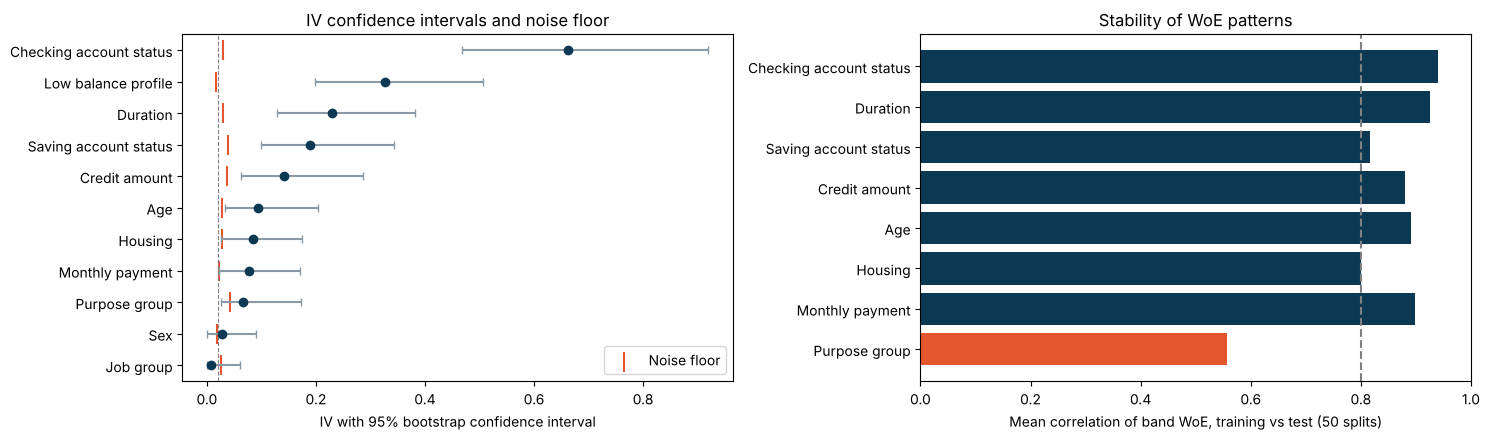

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
d = ci.iloc[::-1]
axes[0].errorbar(d['IV'], range(len(d)), xerr=[d['IV'] - d['CI low (2.5%)'], d['CI high (97.5%)'] - d['IV']],
                 fmt='o', color='#0B3954', ecolor='#8A99A6', capsize=3)
axes[0].scatter(nf.iloc[::-1]['Noise floor (95%)'], range(len(d)), marker='|', s=200, color='#E4572E', label='Noise floor')
axes[0].set_yticks(range(len(d))); axes[0].set_yticklabels(d['Feature'])
axes[0].axvline(0.02, color='grey', linestyle='--', linewidth=0.8)
axes[0].set_xlabel('IV with 95% bootstrap confidence interval'); axes[0].legend()
axes[0].set_title('IV confidence intervals and noise floor')

s = stability.iloc[::-1]
axes[1].barh(s['Feature'], s['Mean WoE correlation'], color=['#E4572E' if v < 0.8 else '#0B3954' for v in s['Mean WoE correlation']])
axes[1].axvline(0.8, color='grey', linestyle='--')
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Mean correlation of band WoE, training vs test (50 splits)')
axes[1].set_title('Stability of WoE patterns')
plt.tight_layout()
plt.show()

## 9. Final feature selection

Each feature's decision is based on all the evidence above.

In [12]:
tiers = {'checking_status': 'Tier 1 - Critical', 'duration_bin': 'Tier 2 - Important', 'saving_status': 'Tier 2 - Important',
         'credit_bin': 'Tier 2 - Important', 'payment_bin': 'Tier 2 - Important', 'age_bin': 'Tier 3 - Supporting',
         'housing': 'Tier 3 - Supporting', 'purpose_group': 'Tier 3 - Supporting'}
stab = stability.set_index('Feature')
sig = significance.set_index('Feature')

rows = []
for f in features:
    n = names[f]
    if f in selected:
        unstable = stab.loc[n, 'Pattern'] == 'Unstable'
        decision = 'Keep - monitor' if unstable else 'Keep'
        reason = ('Small, consistent gain, but its risk pattern is unstable across samples; recheck when more data is available'
                  if unstable else 'Above noise floor, stable pattern and significant in the model')
        rows.append([n, tiers[f], round(iv_full[f], 3), f'{ci.set_index("Feature").loc[n, "CI low (2.5%)"]:.3f} to {ci.set_index("Feature").loc[n, "CI high (97.5%)"]:.3f}',
                     stab.loc[n, 'Mean WoE correlation'], sig.loc[n, 'p-value'], decision, reason])
    else:
        reason = {'low_balance_profile': 'Strong but duplicates Checking account status (r = 0.64)',
                  'sex': 'Protected characteristic; weak, unreliable signal (41% chance its IV is below 0.02)',
                  'job_group': 'IV below 0.02 and within the noise floor'}[f]
        rows.append([n, 'Excluded', round(iv_full[f], 3), f'{ci.set_index("Feature").loc[n, "CI low (2.5%)"]:.3f} to {ci.set_index("Feature").loc[n, "CI high (97.5%)"]:.3f}',
                     np.nan, np.nan, 'Drop', reason])

final_selection = pd.DataFrame(rows, columns=['Feature', 'Tier', 'IV', 'IV 95% CI', 'WoE stability', 'p-value', 'Decision', 'Reason'])
final_selection

,Feature,Tier,IV,IV 95% CI,WoE stability,p-value,Decision,Reason
0,Checking account status,Tier 1 - Critical,0.662,0.467 to 0.919,0.940,0.0000,Keep,"Above noise floor, stable pattern and significant in the model"
1,Low balance profile,Excluded,0.327,0.198 to 0.507,NaN,NaN,Drop,Strong but duplicates Checking account status (r = 0.64)
2,Duration,Tier 2 - Important,0.230,0.128 to 0.382,0.925,0.0007,Keep,"Above noise floor, stable pattern and significant in the model"
3,Saving account status,Tier 2 - Important,0.189,0.100 to 0.344,0.817,0.0001,Keep,"Above noise floor, stable pattern and significant in the model"
4,Credit amount,Tier 2 - Important,0.142,0.062 to 0.286,0.880,0.0000,Keep,"Above noise floor, stable pattern and significant in the model"
5,Age,Tier 3 - Supporting,0.093,0.033 to 0.204,0.891,0.0022,Keep,"Above noise floor, stable pattern and significant in the model"
6,Housing,Tier 3 - Supporting,0.084,0.025 to 0.174,0.801,0.0253,Keep,"Above noise floor, stable pattern and significant in the model"
7,Monthly payment,Tier 2 - Important,0.077,0.023 to 0.171,0.899,0.0000,Keep,"Above noise floor, stable pattern and significant in the model"
8,Purpose group,Tier 3 - Supporting,0.066,0.026 to 0.172,0.557,0.0226,Keep - monitor,"Small, consistent gain, but its risk pattern is unstable across samples; recheck when more data is available"
9,Sex,Excluded,0.027,0.001 to 0.090,NaN,NaN,Drop,"Protected characteristic; weak, unreliable signal (41% chance its IV is below 0.02)"


In [13]:
final_list = final_selection[final_selection['Decision'] != 'Drop'].copy()
final_list.insert(0, 'Column', [f for f in features if f in selected])
final_list['WoE column'] = 'woe_' + final_list['Column']
final_list.to_csv('data/processed/final_feature_list.csv', index=False)
print('Saved data/processed/final_feature_list.csv with', len(final_list), 'features')
final_list[['Column', 'WoE column', 'Feature', 'Tier', 'Decision']]

Saved data/processed/final_feature_list.csv with 8 features


,Column,WoE column,Feature,Tier,Decision
0,checking_status,woe_checking_status,Checking account status,Tier 1 - Critical,Keep
2,duration_bin,woe_duration_bin,Duration,Tier 2 - Important,Keep
3,saving_status,woe_saving_status,Saving account status,Tier 2 - Important,Keep
4,credit_bin,woe_credit_bin,Credit amount,Tier 2 - Important,Keep
5,age_bin,woe_age_bin,Age,Tier 3 - Supporting,Keep
6,housing,woe_housing,Housing,Tier 3 - Supporting,Keep
7,payment_bin,woe_payment_bin,Monthly payment,Tier 2 - Important,Keep
8,purpose_group,woe_purpose_group,Purpose group,Tier 3 - Supporting,Keep - monitor


## 10. Quick checks

In [14]:
woe_file = pd.read_csv('data/processed/german_credit_woe.csv')
checks = {
    'Saved IVs reproduce from the data (difference below 0.001)': (repro['Match'] == 'Yes').all(),
    'Every selected feature has a bootstrap CI lower bound above 0.02': (ci.set_index('Feature').loc[[names[f] for f in selected], 'CI low (2.5%)'] > 0.02).all(),
    'Every selected feature is above its noise floor': all(iv_full[f] > noise_floor[f] for f in selected),
    'Job group is below its noise floor': iv_full['job_group'] < noise_floor['job_group'],
    'All PSI values are below 0.1': all(np.max(psi[f]) < 0.1 for f in selected),
    'All VIF values are below 5': (vif['VIF'] < 5).all(),
    'All 8 features are significant in the model (p < 0.05)': (significance['p-value'].iloc[1:] < 0.05).all(),
    'All model coefficients are negative': (logit.params.iloc[1:] < 0).all(),
    'Hold-out ROC-AUC above 0.7': holdout.loc[1, 'ROC-AUC'] > 0.7,
    'KS above 0.4': ks > 0.4,
    'All 8 features give the best mean hold-out ROC-AUC': repeated['Mean hold-out ROC-AUC'].idxmax() == 0,
    'Final feature list matches the WoE dataset columns': set(final_list['WoE column']) == set(woe_file.columns) - {'bad'},
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Saved IVs reproduce from the data (difference below 0.001)
PASS - Every selected feature has a bootstrap CI lower bound above 0.02
PASS - Every selected feature is above its noise floor
PASS - Job group is below its noise floor
PASS - All PSI values are below 0.1
PASS - All VIF values are below 5
PASS - All 8 features are significant in the model (p < 0.05)
PASS - All model coefficients are negative
PASS - Hold-out ROC-AUC above 0.7
PASS - KS above 0.4
PASS - All 8 features give the best mean hold-out ROC-AUC
PASS - Final feature list matches the WoE dataset columns

All 12 checks passed


## 11. Conclusion

**The WoE / IV findings are confirmed.** The saved results reproduce exactly, every selected feature is well above the noise floor
with a bootstrap confidence interval clear of 0.02, the bands are stable (all PSI below 0.1), the features do not overlap (all VIF below 1.5)
and all eight are significant in the model. On unseen customers the features reach a ROC-AUC of about 0.75 to 0.77 and a KS of about 0.5.

**Final feature selection: keep all 8 features.**
- **Tier 1:** Checking account status
- **Tier 2:** Duration, Saving account status, Credit amount, Monthly payment
- **Tier 3:** Age, Housing, Purpose group (Purpose group to be monitored, because its risk pattern is not stable across samples)
- **Dropped:** Low balance profile, Sex, Job group

All 8 features give the best average hold-out ROC-AUC. A 7-feature version without Purpose group performs almost identically
and is an acceptable simpler alternative if a smaller scorecard is preferred.